# Support Vector Machine: Breast Cancer Classification

> **Authorship note.** This notebook was written by Claude (an AI assistant) on 22 November 2026 at the repository owner's request, as a reference implementation. It replaces a notebook that closely followed a public tutorial. It is not the owner's own work, and the owner has not yet reworked it.

Goal: classify tumours as malignant or benign from 30 numeric measurements, and see how feature scaling, the kernel, `C` and `gamma` change an SVM's results.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 1. Load the data

The Wisconsin breast cancer dataset ships with scikit-learn, so no file is needed. Target `0` = malignant, `1` = benign.

In [2]:
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Rows, columns:", X.shape)
print(y.map(dict(enumerate(data.target_names))).value_counts())
X.iloc[:, :6].describe().round(2)

Rows, columns: (569, 30)
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
count,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10
std,3.52,4.30,24.30,351.91,0.01,0.05
min,6.98,9.71,43.79,143.50,0.05,0.02
25%,11.70,16.17,75.17,420.30,0.09,0.06
50%,13.37,18.84,86.24,551.10,0.10,0.09
75%,15.78,21.80,104.10,782.70,0.11,0.13
max,28.11,39.28,188.50,2501.00,0.16,0.35


## 2. Train/test split

`stratify=y` keeps the same malignant/benign ratio in both parts. The test set is only used at the end.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (426, 30)  Test: (143, 30)


## 3. Why scaling matters

An SVM measures distances between points. The features here range from below 1 (smoothness) to over 2,000 (area), so without scaling the large features dominate. Putting `StandardScaler` in a pipeline means it is fitted on the training data only.

In [4]:
unscaled = SVC(kernel="rbf").fit(X_train, y_train)
scaled = make_pipeline(StandardScaler(), SVC(kernel="rbf")).fit(X_train, y_train)

print(f"RBF SVM without scaling - test accuracy: {accuracy_score(y_test, unscaled.predict(X_test)):.3f}")
print(f"RBF SVM with scaling    - test accuracy: {accuracy_score(y_test, scaled.predict(X_test)):.3f}")

RBF SVM without scaling - test accuracy: 0.923
RBF SVM with scaling    - test accuracy: 0.979


## 4. Compare kernels

The kernel decides the shape of the boundary: a straight hyperplane (`linear`), a curved one (`poly`), or a flexible one built from distances to the support vectors (`rbf`). Each is scored with 5-fold cross-validation on the training set.

In [5]:
from sklearn.model_selection import cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for kernel in ["linear", "poly", "rbf"]:
    model = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    rows.append({"kernel": kernel, "mean CV accuracy": scores.mean(), "std": scores.std()})
pd.DataFrame(rows).round(3)

,kernel,mean CV accuracy,std
0,linear,0.972,0.012
1,poly,0.894,0.036
2,rbf,0.967,0.005


## 5. Tune `C` and `gamma`

- `C` trades a wide margin (small `C`) against classifying every training point correctly (large `C`).
- `gamma` sets how far one training point's influence reaches in the RBF kernel: large values make the boundary very wiggly.

`GridSearchCV` tries every combination with cross-validation and keeps the best.

In [6]:
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1],
}
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="accuracy")
search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print(f"Best mean CV accuracy: {search.best_score_:.3f}")

Best parameters: {'svc__C': 10, 'svc__gamma': 0.001}
Best mean CV accuracy: 0.974


In [7]:
# Mean CV accuracy for every C / gamma pair
results = pd.DataFrame(search.cv_results_)
table = results.pivot_table(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score")
table.round(3)

param_svc__gamma,0.001,0.01,0.1,scale
param_svc__C,,,,
0.1,0.706,0.948,0.944,0.951
1.0,0.946,0.965,0.960,0.967
10.0,0.974,0.972,0.946,0.970
100.0,0.970,0.963,0.946,0.958


## 6. Evaluate the tuned model on the test set

Test accuracy: 0.979

              precision    recall  f1-score   support

   malignant       0.98      0.96      0.97        53
      benign       0.98      0.99      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



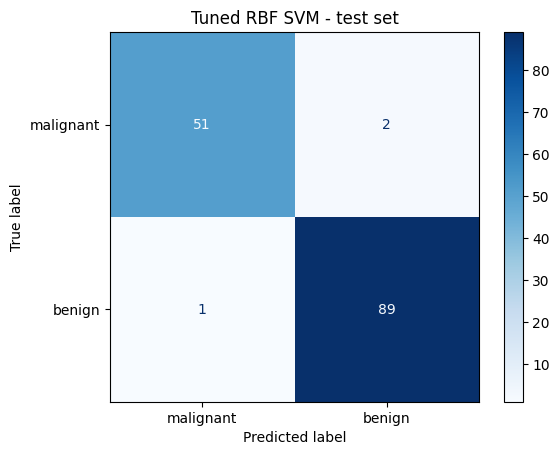

In [8]:
best = search.best_estimator_
y_pred = best.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, target_names=data.target_names))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, cmap="Blues")
plt.title("Tuned RBF SVM - test set")
plt.show()

## 7. Support vectors

Only the training points on or inside the margin (the support vectors) define the boundary. A small share of support vectors usually means a cleaner separation.

In [9]:
svc = best.named_steps["svc"]
for name, count in zip(data.target_names, svc.n_support_):
    print(f"{name}: {count} support vectors")
print(f"Total: {svc.n_support_.sum()} of {len(X_train)} training points")

malignant: 38 support vectors
benign: 40 support vectors
Total: 78 of 426 training points


## Summary

- Scale features before an SVM; the pipeline keeps the scaler from seeing the test data.
- Compare kernels with cross-validation rather than on the test set.
- Tune `C` and `gamma` together, then check the chosen model once on the held-out test set.

The numbers above come from running this notebook; they depend on the random split (`random_state=42`).